# Telco Customer Churn Analysis

## 1. Introduction
Customer churn, when a customer stops using a company's service, is one of the most important problems for subscription businesses such as telecom providers. Acquiring a new customer costs much more than retaining an existing one, so knowing **who** leaves and **why** helps a company reduce revenue loss and improve its retention strategy.



## 2. Problem Statement
A telecom company is losing a significant share of its customers: about **26.54%** of the customers in the dataset have churned. Each lost customer means lost recurring revenue, and replacing them costs more than keeping them. The company does not clearly know which types of customers are most likely to leave or what factors are linked to their decision.

This project analyses customer demographics, account details and subscribed services to understand which factors are most associated with churn, so the company can identify high-risk customers and act before they leave.

## 3. Objectives
- Find the overall churn rate of the company.
- Understand how customer demographics (gender, senior citizen status, partner, dependents) relate to churn.
- Analyse how account details (contract type, tenure, payment method) affect churn.
- Examine how subscribed services (internet service, online security, tech support, streaming and others) are linked to churn.
- Identify the customer groups at the highest risk of churning.
- Suggest practical, data-backed recommendations to improve customer retention.

In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv("Customer Churn.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
df.isnull().sum().sum()

np.int64(0)

In [279]:
df.duplicated().sum()

np.int64(0)

In [280]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


# Data Cleaning.

In [6]:
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors='coerce')

In [7]:
def conve(value):
    if value == 1:
        return "yes"
    else:
        return"no"

df["SeniorCitizen"]=df["SeniorCitizen"].apply(conve)

In [8]:
df=df.fillna(0)

# Data Visualization.

# 1] The total count of churn

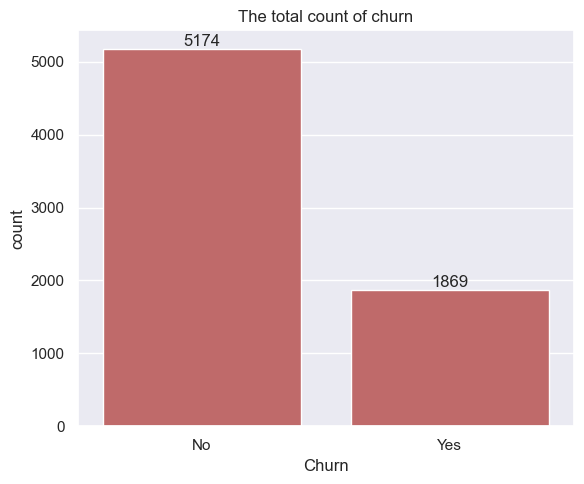

In [9]:
plt.figure(figsize=(6, 5))
sns.set(style="darkgrid")
ax=sns.countplot(data=df,x="Churn",color="indianred")
ax.bar_label(ax.containers[0])
plt.title("The total count of churn")
plt.tight_layout()

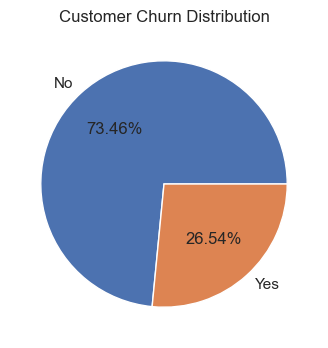

In [10]:
plt.figure(figsize=(4, 4))
sns.set(style="darkgrid")
gb = df["Churn"].value_counts()
plt.pie(gb.values,labels=gb.index,autopct="%1.2f%%")
plt.title("Customer Churn Distribution")
plt.show()

**There are total **26.54%** of the customers who churned.**

# 2] Customer Churn Count by Gender.

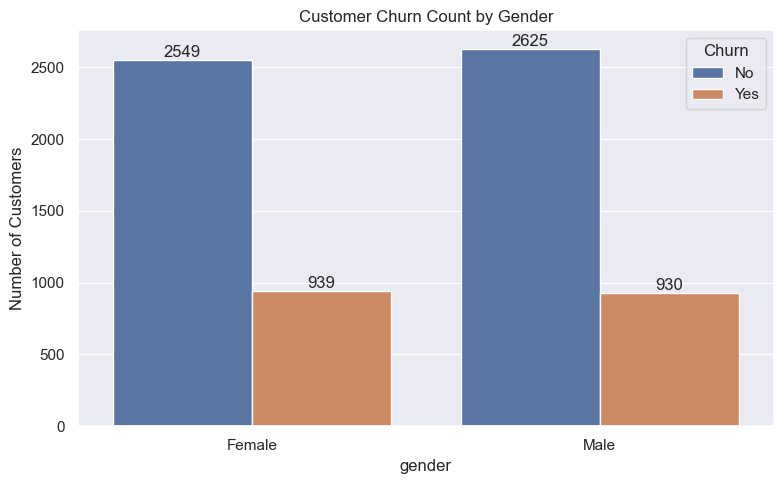

In [11]:
plt.figure(figsize=(8, 5))
sns.set(style="darkgrid")
ax=sns.countplot(data=df,x="gender",hue="Churn",palette="deep")
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
plt.title("The total count of churn")
plt.title("Customer Churn Count by Gender")
plt.xlabel("gender")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

**The Churn of the Customers is not based on the gender.**

# 3]Customer Churn Count by SeniorCitizen

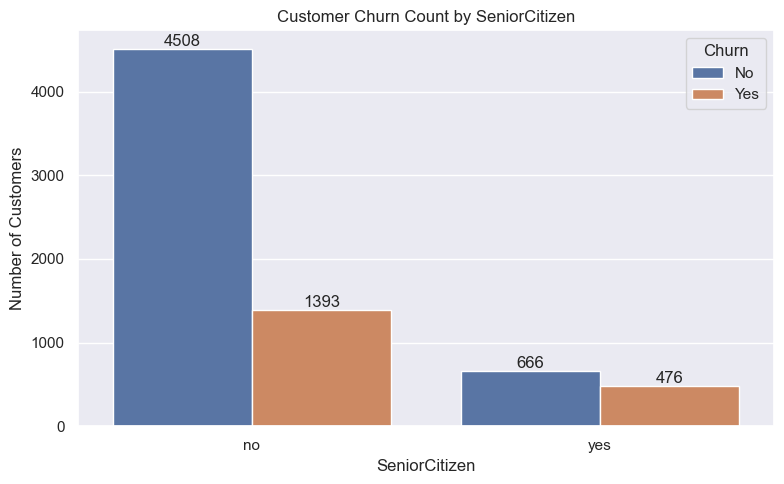

In [12]:
plt.figure(figsize=(8, 5))
sns.set(style="darkgrid")
ax=sns.countplot(data=df,x="SeniorCitizen",hue="Churn",palette="deep")
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
plt.title("The total count of churn")
plt.title("Customer Churn Count by SeniorCitizen")
plt.xlabel("SeniorCitizen")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

**Comparitively, the senior citizen are churned most.**

# 4]Customer Churn Count by The Contract.

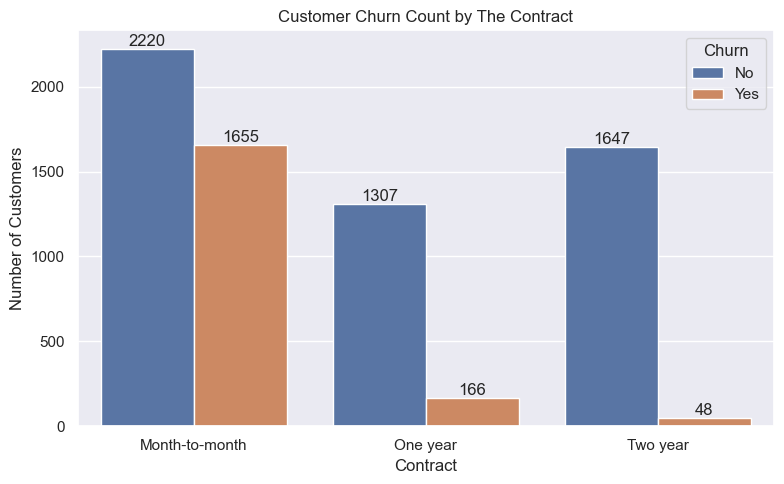

In [15]:
plt.figure(figsize=(8, 5))
sns.set(style="darkgrid")
ax=sns.countplot(data=df,x="Contract",hue="Churn",palette="deep")
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
plt.title("Customer Churn Count by The Contract")
plt.xlabel("Contract")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


**people who have month to month contract are likely to churn then from those who have 1 or 2 years or contract.**

# 5] Customer Churn Count by The Contract.

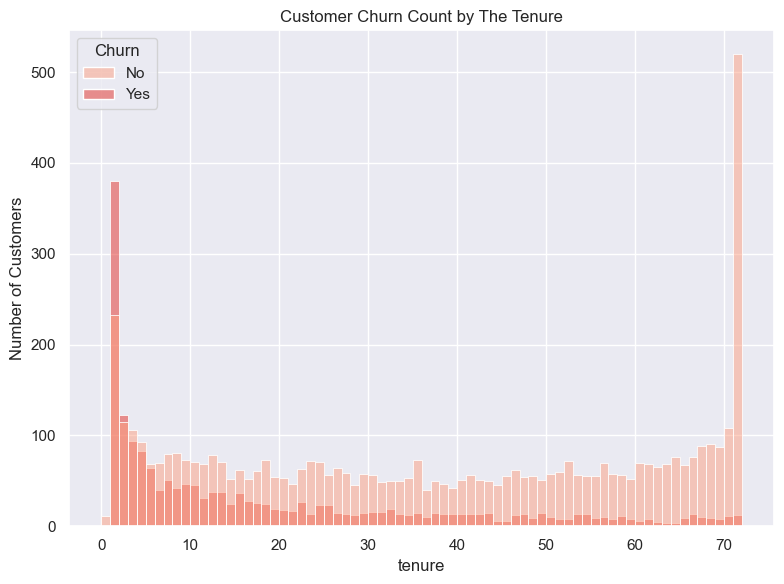

In [289]:
plt.figure(figsize=(8, 6))
sns.set(style="darkgrid")
sns.histplot(x="tenure",data=df,hue="Churn",bins=72,palette="Reds")
plt.title("Customer Churn Count by The Tenure")
plt.xlabel("tenure")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

**The customer who had used ther service for 1 month are churned, the customer who used the service for the more time are not.**

# 6] Customer Churn Count by the various services.

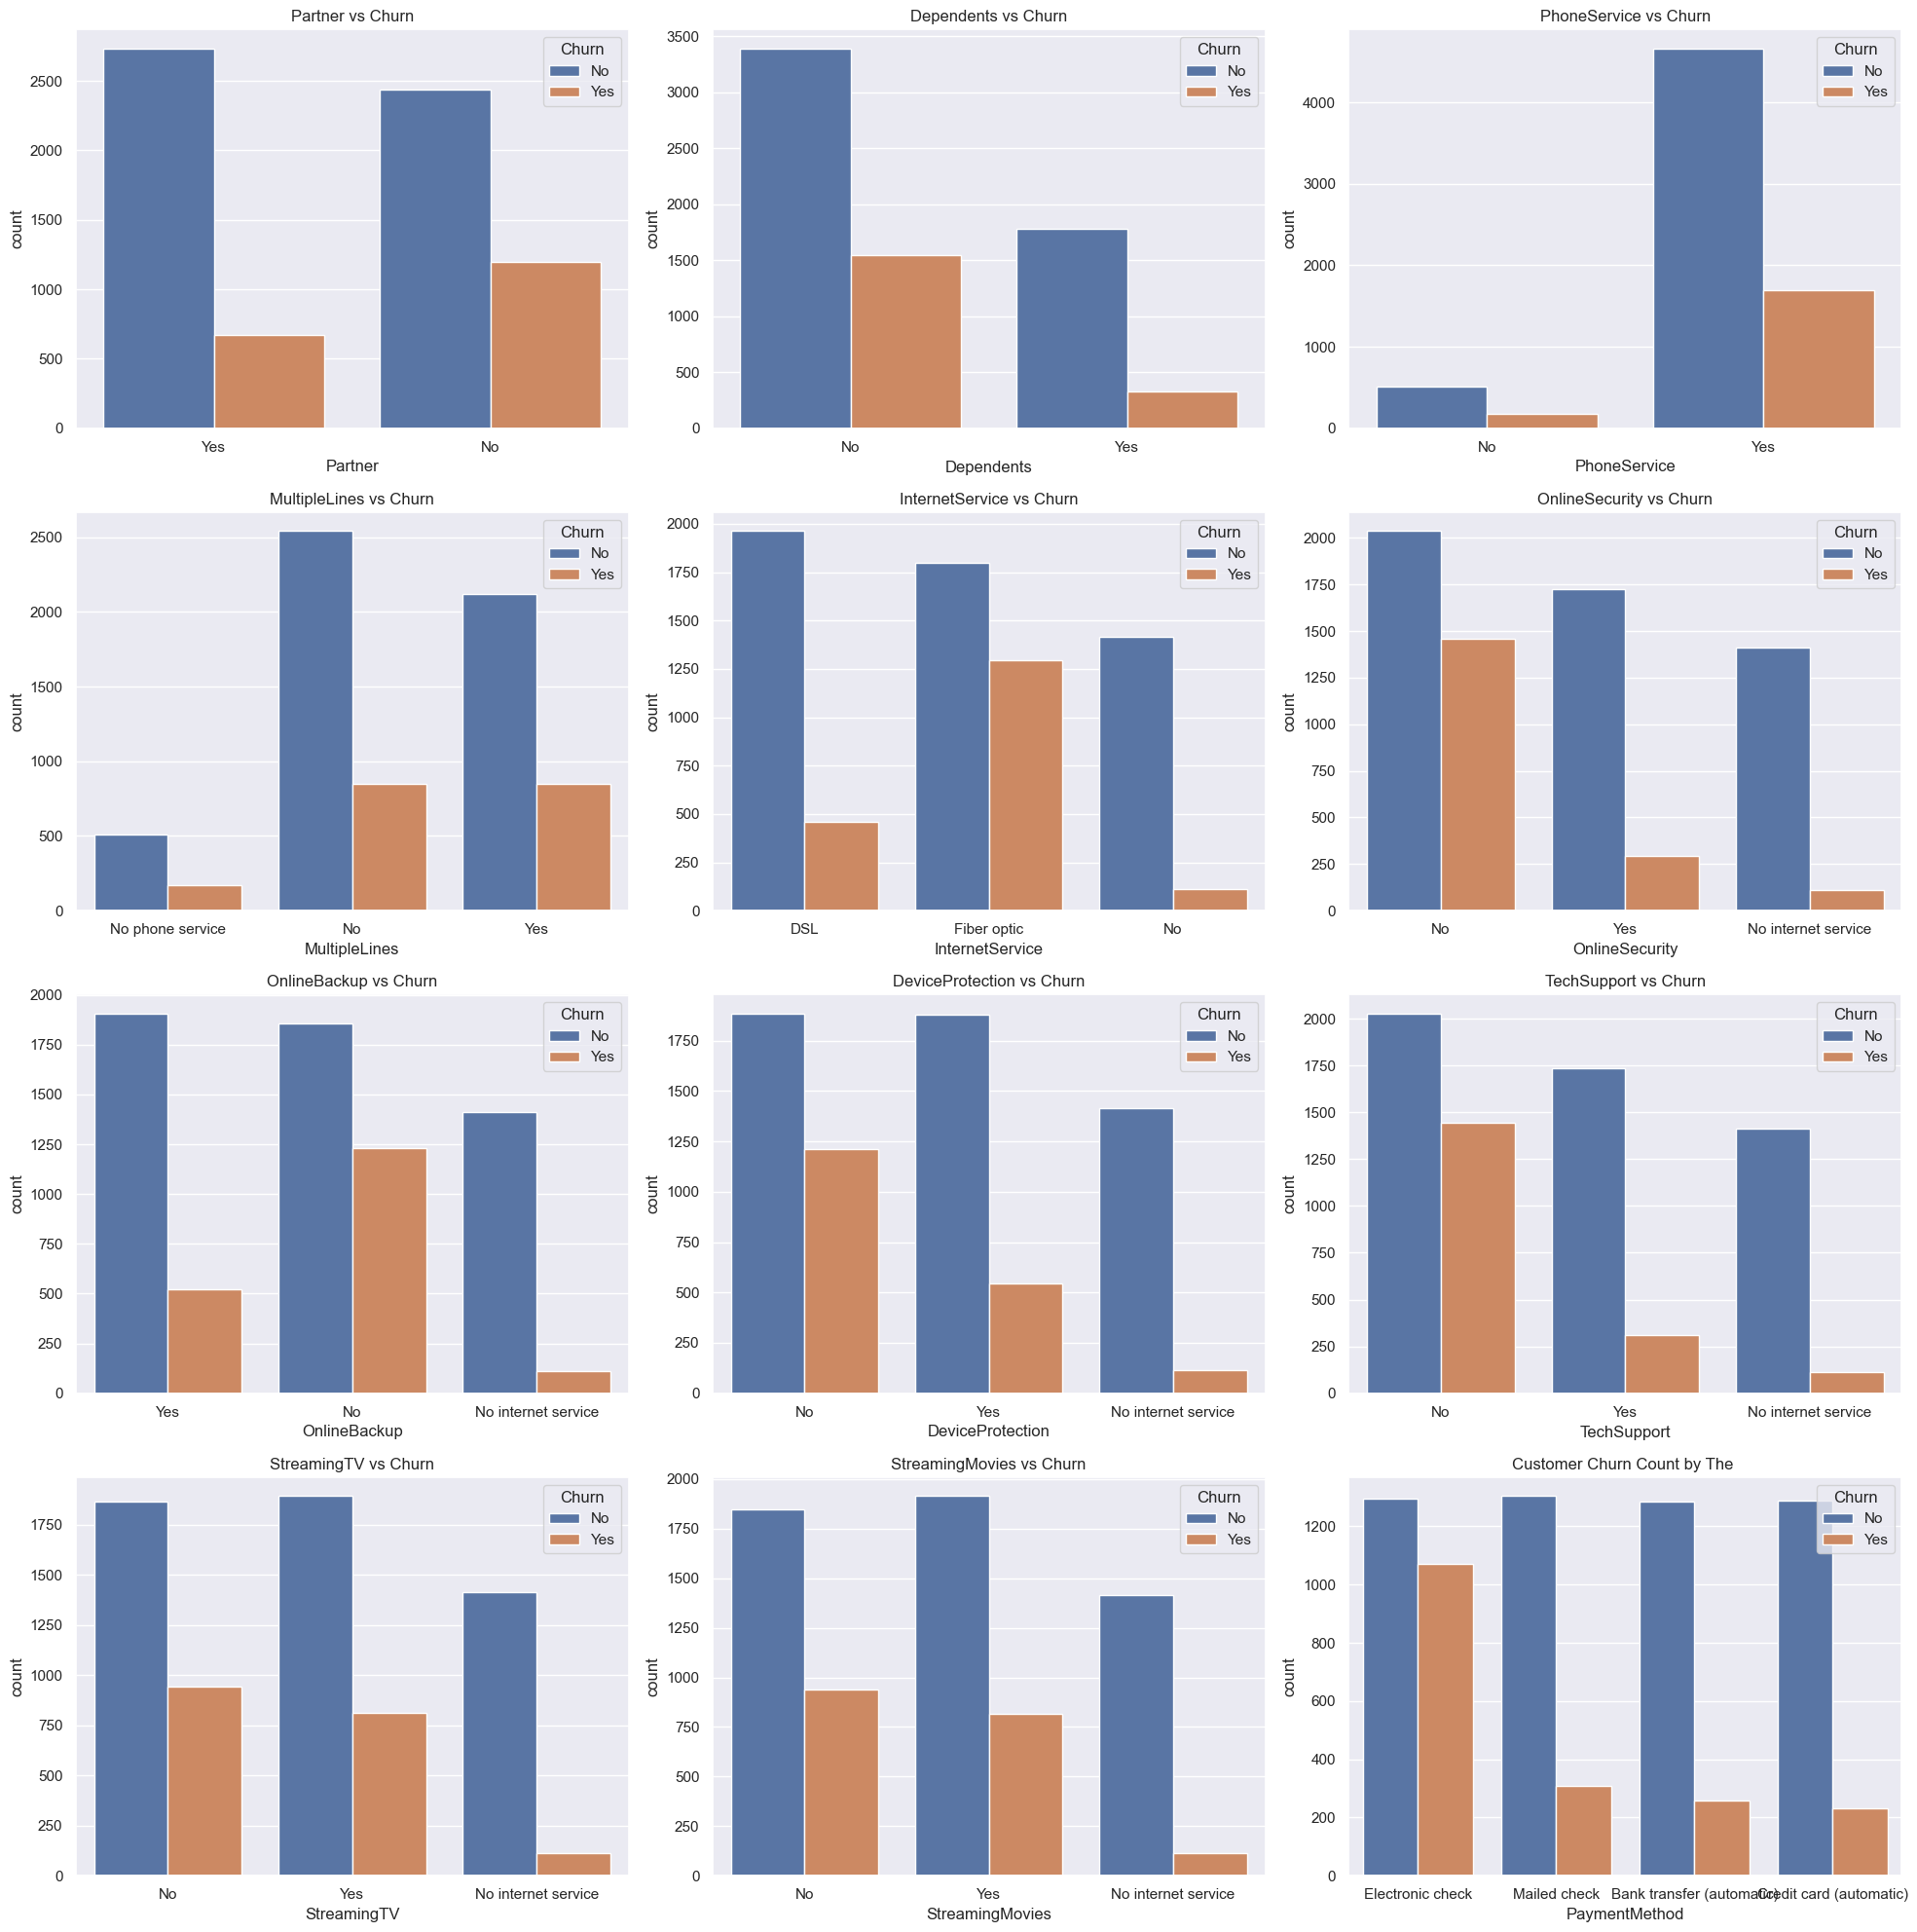

In [301]:
columns = ['Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity','OnlineBackup', 'DeviceProtection', 'TechSupport','StreamingTV', 'StreamingMovies',"PaymentMethod"]
palette = "deep"
fig, ax = plt.subplots(4, 3, figsize=(20, 20))
ax = ax.flatten()
for i, col in enumerate(columns):
    sns.countplot(data=df,x=col,hue='Churn',ax=ax[i],palette=palette)

    ax[i].set_title(f'{col} vs Churn')
    ax[i].tick_params(axis='x')
plt.tight_layout()
plt.show()

# Conclusion: Why Customers Churn

Overall, **26.54%** of customers churned.

**Key drivers**
1. **Contract type:** Month-to-month customers churn at ~43%, versus ~11% (one year) and ~3% (two year). They account for most churners.
2. **Tenure:** Churn is concentrated in the first months of service; long-tenure customers rarely leave.
3. **Internet service:** Fiber optic customers churn at ~42%, versus ~19% for DSL.
4. **Missing support services:** Customers without Online Security or Tech Support churn at ~42%, versus ~15% for those with them.
5. **Payment method:** Electronic check users churn at about 45%, far above automatic payment methods (about 15-17%).
6. **Customer profile:** Senior citizens (~42% vs ~24%), customers without a partner, and customers without dependents churn more.



**Not significant:** gender, phone service, multiple lines, streaming TV and streaming movies.



**Recommendations**
- Offer incentives to move month-to-month customers onto 1 or 2-year contracts.
- Focus onboarding and retention efforts on the first 3 to 6 months.
- Bundle Tech Support and Online Security, especially for fiber customers.
- Encourage automatic payments with a small discount.
- Run targeted retention offers for senior citizens and single customers.

